<table>
    <tr>
        <td><img src="https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/logo_ECI.png" width="300"/></td>
        <td>&nbsp;</td>
        <td>
            <h1 style="font-size:200%;color:blue;text-align:center">    <FONT COLOR="blue">  Redes Neuronales </p> Arquitectura en Tensorflow </p> Class and Regre</p>     </h1></td>         
        <td>
            <tp><p style="font-size:99%;text-align:center">Diplomado</p></tp>
            <tp><p style="font-size:115%;text-align:center">Ciencia de Datos 2026-2</p></tp>
            <tp><p style="font-size:115%;text-align:center">Prof. Fabián Sánchez</p></tp>
        </td>
    </tr>
</table>

# <FONT SIZE=5 COLOR="purple"> 1. Introducción redes neuronales </FONT>

En este notebook haremos una introducción a los conceptos fundamentales de las redes neuronales y exploraremos un ejemplo ilustrativo con un conjunto de datos estructurado con el fin de revisar como generar la arquitectura de la red neuronal usando el perceptron multicapa de *skilearn* y luego con la librería *keras* y *tensorflow*. En un próximo notebook trabajaremos con *pytorch*

Iniciaremos indicando los conceptos fundamentales.

- Las redes neuronales artificiales o (ANN, artificial neural networks) son algoritmos de machine learning cuyo funcionamiento está inspirado en el funcionamiento de la neurona biológica y sus conexiones entre si.

<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/86206b1c9e9fe0b3caac025f9abfb1c0c526d973/Redes/neurona_vs_redes.png?raw=true" width="700" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración con Chat GPT   </FONT> <figcaption></center>
<br>


- La estructura de una red neuronal tiene la siguiente forma

     - Capa de entrada
     - Capas ocultas intermedias
     - Capa de salida


<br>
<center><img src="https://github.com/Fabian830348/cursos/blob/master/Redes/redes3.png?raw=true" width="700" height="400"></center> <center><figcaption> <FONT SIZE=1 COLOR="black"> Fuente: Elaboración propia </FONT> <figcaption></center>
<br>

Cada una de estas capas está compuesta por nodos o neuronas que se conectan con otras y tienen asociadas pesos $w_{ij}$ y un bias $b_{j}$.

Cuando la salida de cualquier nodo está por encima del valor de umbral determinado, ese nodo se activa y envía datos de salida a la siguiente capa de la red. En caso contrario, no se pasan datos a la siguiente capa.







In [1]:
# Manipulación de data.frames
import pandas as pd
import numpy as np

# Librerías para Gráficos
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Librerías para datos de entrenamiento y prueba
from sklearn.model_selection    import train_test_split

# Para preprocesamiento
from sklearn.preprocessing      import StandardScaler, MinMaxScaler
from sklearn.preprocessing      import LabelEncoder, OneHotEncoder
from sklearn.compose            import ColumnTransformer
from sklearn.pipeline           import Pipeline

# Librerías para perceptrón y ANN-multicapa con sklearn
from sklearn.linear_model       import Perceptron    #(clasificación binaria)
from sklearn.neural_network     import MLPClassifier # (multiclase)

# Para trabajar redes con Keras.

from tensorflow.keras.models    import Sequential
from tensorflow.keras.layers    import Dense, Input
from tensorflow.keras.layers    import Dropout
from keras.callbacks            import EarlyStopping, LearningRateScheduler
from tqdm.keras                 import TqdmCallback

# Métricas de evaluación
from sklearn.metrics            import confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.metrics            import accuracy_score, precision_score, recall_score, f1_score
from imblearn.metrics           import specificity_score

# Optimización de hiperparámetros
from sklearn.model_selection    import GridSearchCV, RandomizedSearchCV

# Para ignorar los warnings
import warnings
warnings.filterwarnings("ignore")

In [2]:
def evaluacion_modelo(modelo, X_train, y_train, X_test, y_test, nombre_modelo = "modelo",graficar = True):
  # definir las predicciones en conjuntos de train y test
  y_pred_train = modelo.predict(X_train)
  y_pred_test  = modelo.predict(X_test)
  # matrices de confusión
  if graficar :
    # Calcular matrices de confusión
    cm_train = confusion_matrix(y_train, y_pred_train)
    cm_test = confusion_matrix(y_test, y_pred_test)
    # ejes para gráficas
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    # matriz de confusión en train
    sns.heatmap(pd.DataFrame(cm_train),                # data.frame
                  annot=True,                          # colocar números de las cajitas
                  annot_kws = {'size':20},             # tamaño de la letra
                  cmap="YlOrRd",                       # color de la letra 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu'
                  fmt='g',                             # para que salgan los número no : notación científica
                  ax=axes[0])
    axes[0].set_title(f'Matriz de Confusión - Train-{nombre_modelo}', fontsize=14)
    axes[0].set_xlabel('Predicciones')
    axes[0].set_ylabel('Valores Reales')
    # matriz de confusión en test
    sns.heatmap(pd.DataFrame(cm_test),
              annot=True,
              fmt='g',
              cmap='YlOrRd',
              annot_kws={'size':20},
              ax=axes[1])
    axes[1].set_title(f'Matriz de Confusión - Test-{nombre_modelo}', fontsize=14)
    axes[1].set_xlabel('Predicciones')
    axes[1].set_ylabel('Valores Reales')
    plt.tight_layout()
    plt.show()
  # metricas en train
  metrics=["accuracy", "recall" , "specificity", "precision", "f1"]
  # valores
  values_train = [accuracy_score(y_train,y_pred_train),
          recall_score(y_train,y_pred_train),
          specificity_score(y_train,y_pred_train),
          precision_score(y_train,y_pred_train),
          f1_score(y_train,y_pred_train)]
  values_test = [accuracy_score(y_test,y_pred_test),
          recall_score(y_test,y_pred_test),
          specificity_score(y_test,y_pred_test),
          precision_score(y_test,y_pred_test),
          f1_score(y_test,y_pred_test)]

  df = pd.DataFrame({f"{nombre_modelo}_train" : values_train,
                      f"{nombre_modelo}_test" : values_test}, index = metrics)
  return df

# <FONT SIZE=5 COLOR="purple"> 2. Ejemplo de Clasificación con Tensorflow</FONT>
   


## <FONT SIZE=4 COLOR="blue"> 2.1 Contexto </FONT>

En este caso intentaremos predecir a qué categoría corresponde un conjunto de datos, es decir, un problema de clasificación binaria. Usaremos la configuración en tensorflow

Queremos predecir si una integrante de una muestra que representa a una población, en este caso de Indias Pima, tiene diabetes. Queremos hacer esto a partir de múltiples variables que tenemos de cada uno de los pacientes:

| Variable                     | Descripción                                                                                                                                                                                                                                      |
| ---------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| **Pregnancies**              | Número de embarazos que ha tenido la paciente.                                                                                                                                                                                                   |
| **Glucose**                  | Concentración de glucosa plasmática, expresada en mg/dL. Es una variable relevante para evaluar alteraciones en el metabolismo de la glucosa.                                                                                                    |
| **BloodPressure**            | Presión arterial diastólica, expresada en mmHg.                                                                                                                                                                                                  |
| **SkinThickness**            | Grosor del pliegue cutáneo del tríceps, expresado en milímetros. Se utiliza como indicador indirecto de grasa corporal.                                                                                                                          |
| **Insulin**                  | Concentración de insulina sérica, expresada en µU/mL.                                                                                                                                                                                            |
| **BMI**                      | Índice de masa corporal (*Body Mass Index*), expresado en kg/m² y calculado a partir del peso y la estatura.                                                                                                                                     |
| **DiabetesPedigreeFunction** | Índice numérico derivado que representa la influencia de los antecedentes familiares de diabetes. Valores mayores indican una mayor predisposición familiar. Es una variable propia del conjunto de datos Pima y no una prueba clínica estándar. |
| **Age**                      | Edad de la paciente, expresada en años.                                                                                                                                                                                                          |
| **Outcome**                  | Variable objetivo que indica la clasificación de diabetes: **0 = no presenta diabetes** y **1 = presenta diabetes**.

## <FONT SIZE=4 COLOR="blue"> 2.2 Importar los datos </FONT>

Vamos a traer los datos del GitHub de la siguiente manera.

In [3]:
diabetes= pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/pima_diabetes_2000.csv")

## <FONT SIZE=4 COLOR="blue"> 2.3 Exploración de los datos </FONT>

Vamos a realizar una exploración rápida de los datos

In [4]:
# los primeros datos de la tabla
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,7,160,82,16,307,28.79,0.29,40,1
1,9,135,75,28,107,36.00,0.55,45,1
2,1,102,38,10,36,29.16,0.88,30,0
3,4,139,75,28,227,34.81,0.93,34,1
4,7,133,80,38,285,44.68,0.36,47,1


In [5]:
# el tamaño de los datos
diabetes.shape

(2000, 9)

In [6]:
# la información de la variables
diabetes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               2000 non-null   int64  
 1   Glucose                   2000 non-null   int64  
 2   BloodPressure             2000 non-null   int64  
 3   SkinThickness             2000 non-null   int64  
 4   Insulin                   2000 non-null   int64  
 5   BMI                       2000 non-null   float64
 6   DiabetesPedigreeFunction  2000 non-null   float64
 7   Age                       2000 non-null   int64  
 8   Outcome                   2000 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 140.8 KB


In [7]:
# resumen estadístico
diabetes.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,3.917000,119.578000,68.950500,23.027000,96.374000,32.069805,0.469155,33.424000,0.349000
std,2.617544,28.304337,15.105202,10.439864,92.696502,5.986272,0.245845,9.450179,0.476773
min,0.000000,41.000000,0.000000,5.000000,2.000000,12.200000,0.080000,21.000000,0.000000
25%,2.000000,99.000000,64.000000,15.000000,31.000000,27.947500,0.290000,26.000000,0.000000
50%,4.000000,115.000000,71.000000,23.000000,74.500000,31.815000,0.420000,31.000000,0.000000
75%,6.000000,138.000000,77.000000,31.000000,131.000000,35.862500,0.590000,40.000000,1.000000
max,14.000000,199.000000,106.000000,66.000000,690.000000,62.240000,2.190000,73.000000,1.000000


In [8]:
# frecuencias de la variable objetivo
diabetes.Outcome.value_counts()

,count
Outcome,
0,1302
1,698


In [9]:
px.bar(diabetes.Outcome.value_counts(),
       color = diabetes.Outcome.value_counts().index)

Se debe tener en cuenta que los datos están desbalanceados. Sin embargo, para el propósito de este ejercicio los tomaremos de esta forma.

## <FONT SIZE=4 COLOR="blue"> 2.4 Conjunto de Entrenamiento, Validación y Prueba </FONT>

En el caso de las redes neuronales se tienen que ajustar una cantidad importante de hiperparámetros. Por esta razón es importante dividir el conjunto entre conjuntos.

- **Conjunto de Entrenamiento (train):** Datos que usamos para entrenar el modelo. Permite ajustar los pesos

- **Conjunto de Validación: (validation)** Datos para ajustar hiperparámetros.

- **Conjunto de prueba (test):** Datos que se usan para evaluar el rendimiento final y generalización del modelo

Normalmente, usamos $70\%-20\%-10%$ / $60\%-20\%-20%$

## <FONT SIZE=4 COLOR="blue"> 2.5 Escalar las variables predictoras </FONT>

- En general es importante escalar las variables, ya que esto ayuda al algoritmo del descenso del gradiente en el proceso de optimización.

- Una recomendación es hacer el escalamiento después de dividir en entrenamiento y prueba. Ya que la idea es que no se sobreentrene el modelo.

Definimos las variables: objetivo y predictoras o características

In [10]:
# 1. definir las variables
# la variable objetivo
y = diabetes["Outcome"]
# las variables predictoras
X = diabetes.drop("Outcome", axis=1)

# dividir en los tres conjuntos
# 2. Dividimos en entrenamiento (60%) y el otro (40%) lo denominamos temporal ya que se va a volver a dividir
X_train, X_temp, y_train, y_temp = train_test_split(X,                        # variables predictoras
                                                    y,                        # variable de respuesta
                                                    random_state = 0,         # semilla para que al ejecutar siempre de igual
                                                    stratify=y,               # estratificamos con respecto a y (asegura que se mantenga la proporción de clases en y)
                                                    test_size = 0.4)          # tamaño del conjunto de prueba

X_val, X_test, y_val, y_test = train_test_split(X_temp,                       # variables predictoras
                                                y_temp,                       # variable de respuesta
                                                random_state = 0,             # semilla para que al ejecutar siempre de igual
                                                stratify=y_temp,              # estratificamos con respecto a y_temp
                                                test_size = 0.5)              # tamaño del conjunto de prueba

# 3 . escalar los datos
escalar = StandardScaler()
X_train_s = escalar.fit_transform(X_train)
X_val_s = escalar.transform(X_val)
X_test_s = escalar.transform(X_test)

## <FONT SIZE=4 COLOR="magenta"> 2.5 Modelo en TensorFlow-Keras </FONT>

- *TensorFlow* es una librería de Deep Learning en Python desarrollada por google.

- *Keras* es una librería en Python desarrollada por François Chollet (ingeniero de Google) que en esencia es un wrapper sobre TensorFlow , Theano y CNTK: [Ver](https://github.com/keras-team/keras)

- TensorFlow (V1), Theano y CNTK son librerías muy fuertes pero no son muy intuitivas de manejar. Por esta razón Keras empezó a desarrollarse por Chollet con el fin de crear una librería más sencilla de utilizar para aplicaciones de Deep Learning.

- TensorFlow (con el objetivo de simplificar y democratizar el uso de su librería) se integro con el API de Keras, para hacer un uso más sencillo de su librería. Esto es así a partir de la versión 2 de TensorFlow.

- La librería Keras tiene las siguientes características:

    - ***Modularidad***: Una red neuronal se entiende como una secuencia o grafo de capas de neuronas.

    - ***Minimalismo***: Es muy "limpia y sencilla" para crear y entrenar redes maximizando la legibilidad del código.

    - ***Extensibilidad***: Los nuevos componentes tienen que ser fáciles de añadirse a Keras.

    - ***Python***: Keras es Python nativo.

**Modelos en TensorFlow - Keras**

De manera general, los pasos para entrenar una red neuronal son los siguientes

1. ***Definir el modelo***: crear el ***Sequential model*** y añadir las capas con su configuración. [ver](https://www.tensorflow.org/api_docs/python/tf/keras/Sequential).

2. ***Compilar el modelo***: definir o especificar la función de pérdida y llamar al método ***compile()***.

3. ***Ajustar (fit) el modelo***: entrenar el modelo con los datos de entrenamiento llamando al método ***fit()***.

4. ***Realizar predicciones***: usando el modelo se pueden realizar predicciones con nuevos datos llamando a los métodos ***evaluate()*** o ***predict()***.

Realizaremos el ejemplo del conjunto de datos *diabetes* usando ***tensorflow.keras***

- Primero creamos el modelo usando la instrucción Sequential().

- Esto se usa para agrupar una secuencia lineal de capas de redes neuronales en un solo modelo.

In [11]:
model = Sequential()

- Luego utilizamos el método **add** para agregar una capa de nodos al modelo secuencial.

- Agregamos una capa **Dense**, lo que significa que todos los nodos de la capa están conectados a todas las entradas y salidas.

- Las capas densas también se denominan capas completamente conectadas.

- Si la variable objetivo es dicotómica, solo dos categorías usamos una capa final de 1 salida con activación, por ejemplo, ***sigmoide***

- Si la variable objetivo es multiclase, usamos una capa final con el número de clases con activación, por ejemplo, ***softmax***

In [12]:
# fijamos una semilla para que sea reproducible
np.random.seed(2)

# número de variables
n_columnas = 8

# iniciamos el modelo
model = Sequential()

# número de entradas
model.add(Input(shape=(n_columnas,)))

# ponemos una capa intermedia con 16 neuronales (se puede modificar)
model.add(Dense(16, activation='relu'))

# ponemos una capa adicional de 5 neuronas
model.add(Dense(8, activation='relu'))

# la capa de salida va asociada a la clasificación binaria
model.add(Dense(1, activation='sigmoid'))

# multiclase dense( número de clases, activación = "softmax")

Veamos el resumen de la cantidad de parámetros del modelo

In [13]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289 (1.13 KB)

 Trainable params: 289 (1.13 KB)

 Non-trainable params: 0 (0.00 B)

Ahora, generamos la compilación del modelo. Debemos estipular tres elementos:

- **Función de pérdida** (loss). Para este caso binary_crossentropy por ser un problema de clasificación binaria.

- **Optimizador**: se pueden seleccionar varios. Usaremos Adam.

- **métrica**: usaremos el *accuracy*

In [14]:
model.compile(loss='binary_crossentropy',   # binario , multiclase: categorical_crossentropy
              optimizer='adam',             # ver más optimización
              metrics=['accuracy'])         # accuracy = score

Luego, entrenamos el modelo

In [15]:
# entrenamos el modelo
model.fit(X_train_s,                            # conjunto de entrenamiento escalado
          y_train,                              # variable de respuesta entrenamiento
          epochs=100,                           # número de veces o iteraciones de ajustes de pesos.
          validation_data=(X_val_s, y_val),     # conjunto de validación
          verbose = 0,                          # mostrar o no resultados
          callbacks=[TqdmCallback()]            # barra de progreso
          )

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Evaluamos el modelo

In [16]:
scores = model.evaluate(X_test_s, y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8750 - loss: 0.2756


In [17]:
print("Función de Pérdida en test", scores[0])
print("Accuracy en test", scores[1])

Función de Pérdida en test 0.27563366293907166
Accuracy en test 0.875


Observe que la función de pérdida es 0.27 y el accuracy en el conjunto de test es 0.87

Podemos colocar todo el código en un solo bloque. Así:

In [19]:
import tensorflow as tf
import random
SEED = 42
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

# Definir el modelo secuencial
model = Sequential()

# número de entradas
model.add(Input(shape=(n_columnas,)))
# ponemos una capa intermedia con 16 neuronales (se puede modificar)
model.add(Dense(16, activation='relu'))
# ponemos una capa adicional de 8 neuronas
model.add(Dense(8, activation='relu'))

# capa final Para clasificación binaria
model.add(Dense(1, activation='sigmoid'))

# Compilar el modelo
model.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

# Entrenar el modelo usando el conjunto de validación explícitamente
history = model.fit(X_train_s,
                    y_train,
                    epochs=10,
                    validation_data=(X_val_s, y_val),
                    verbose=0,
                    callbacks=[TqdmCallback()])

# 5. Evaluar el modelo
print("\n--- Evaluación ---")
print("Pérdida y Accuracy en entrenamiento:", model.evaluate(X_train_s, y_train))
print("Pérdida y Accuracy en validación:  ", model.evaluate(X_val_s, y_val))
print("Pérdida y Accuracy en prueba (test):", model.evaluate(X_test_s, y_test))

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]


--- Evaluación ---
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8675 - loss: 0.3225
Pérdida y Accuracy en entrenamiento: [0.3224840760231018, 0.8675000071525574]
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8625 - loss: 0.3156 
Pérdida y Accuracy en validación:   [0.3156226575374603, 0.862500011920929]
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8625 - loss: 0.2895 
Pérdida y Accuracy en prueba (test): [0.28953492641448975, 0.862500011920929]


El modelo lo guardamos en una variable que se llema *history*. Esta contiene información que podemos usar para hacer las siguientes gráficas.

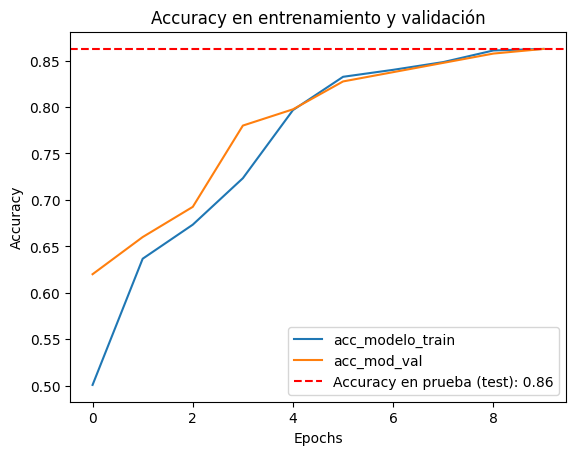

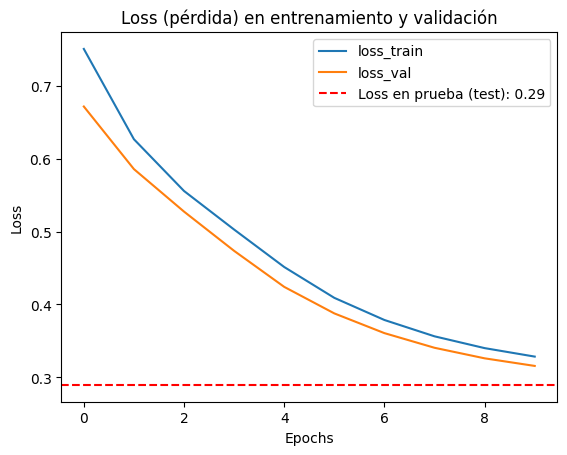

In [20]:
# Gráfica del accuracy del modelo en train y test
loss_test, acc_test = model.evaluate(X_test_s, y_test, verbose=0)
plt.plot(history.history['accuracy'], label = "acc_modelo_train")
plt.plot(history.history['val_accuracy'], label = "acc_mod_val")
plt.axhline(y=acc_test, color='r', linestyle='--', label=f"Accuracy en prueba (test): {acc_test:.2f}")
plt.title("Accuracy en entrenamiento y validación")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Gráfica de la pérdida en test y train
plt.plot(history.history['loss'], label = "loss_train")
plt.plot(history.history['val_loss'], label = "loss_val")
plt.axhline(y=loss_test, color='r', linestyle='--', label=f"Loss en prueba (test): {loss_test:.2f}")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss (pérdida) en entrenamiento y validación")
plt.legend()
plt.show()

***Interpretación:***

- En la gráfica del *Accuracy* se busca que a medida que evolucionen en las *epoch* se incremente este valor tanto en entrenamiento como en prueba. Un valor alto en entrenamiento y bajo en prueba indica posible *overfitting*.

- En la gráfica de la *pérdida* se busca que ambas gráficas sean decrecientes, lo que indicaria que a medida que se avanzan en las *epoch* se va minimizando la función *loss*.



Para hacer la matriz de confusión podemos utilizar lo siguiente.

Primero, miramos las probabilidades

In [21]:
X_test.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
1545,9,129,72,10,249,31.87,0.63,49
1900,1,130,72,21,150,24.90,0.28,27
69,4,137,83,26,62,44.56,0.33,33
1000,7,96,80,35,225,36.33,0.70,46
43,3,89,76,29,111,29.07,0.58,32


In [22]:
# probabilidades
predict = model.predict(X_test_s)
print(predict[0:10])

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
[[0.70249283]
 [0.10060702]
 [0.79472023]
 [0.512569  ]
 [0.08706476]
 [0.6575292 ]
 [0.00883493]
 [0.64137113]
 [0.72668993]
 [0.5613358 ]]


Calculamos las clases de acuerdo con las probabilidades y un umbral de 0.5

In [23]:
y_predict = np.where(model.predict(X_test_s) > 0.5, 1, 0)
y_predict[0:10]

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


array([[1],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1]])

Ahora, construimos la matriz de confusión.

              precision    recall  f1-score   support

           0       0.90      0.89      0.89       261
           1       0.80      0.81      0.80       139

    accuracy                           0.86       400
   macro avg       0.85      0.85      0.85       400
weighted avg       0.86      0.86      0.86       400



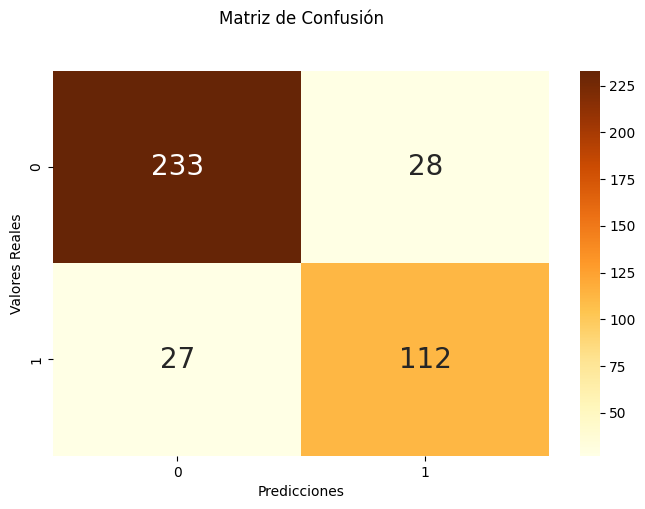

In [24]:
plt.rcParams['figure.figsize'] = (8, 5)
from sklearn import metrics
cm = confusion_matrix(y_test, y_predict)
p = sns.heatmap(pd.DataFrame(cm),                   # data.frame
                annot=True,                         # colocar números de las cajitas
                annot_kws = {'size':20},            # tamaño de la letra
                cmap="YlOrBr",                       # color de la letra
                fmt='g')                            # para que salgan los número no : notación científica
plt.title('Matriz de Confusión', y=1.1)
plt.ylabel('Valores Reales')
plt.xlabel('Predicciones')

print(classification_report(y_test, y_predict))

Ahora, calculamos las métricas

In [25]:
# métricas
metrics=["accuracy", "recall" , "specificity", "precision", "f1"]
values = [accuracy_score(y_test,y_predict),
          recall_score(y_test,y_predict),
          specificity_score(y_test,y_predict),
          precision_score(y_test,y_predict),
          f1_score(y_test,y_predict)]
print("Métricas \n")
evaluacion = pd.DataFrame(values , index = metrics , columns = ["modelo"])
evaluacion

Métricas 



,modelo
accuracy,0.862500
recall,0.805755
specificity,0.892720
precision,0.800000
f1,0.802867


## <FONT SIZE=4 COLOR="magenta"> 2.6 Análisis y predicciones </FONT>

Vamos a realizar las predicciones del conjunto de datos

```python
https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/pima_diabetes_100_para_predecir.csv
```



In [26]:
predicciones = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/pima_diabetes_100_para_predecir.csv")
predicciones.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,167,90,17,266,33.01,0.202,55
1,3,95,60,24,60,30.57,0.655,28
2,5,90,70,34,61,35.34,0.400,24
3,7,140,74,7,40,26.58,0.319,48
4,4,94,64,23,20,27.79,0.421,33


In [27]:
# escalar los datos predicciones
predicciones_scalado = escalar.transform(predicciones)


In [28]:
diabetes_predic = model.predict(predicciones_scalado)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


In [29]:
diabetes_predic

array([[7.65210092e-01],
       [4.16651815e-02],
       [6.30255714e-02],
       [4.53725308e-01],
       [3.04173157e-02],
       [4.09054011e-01],
       [8.50548506e-01],
       [7.90964007e-01],
       [5.66848695e-01],
       [1.46814482e-02],
       [9.06647682e-01],
       [1.43471751e-02],
       [2.20417321e-01],
       [8.82813394e-01],
       [2.82178503e-02],
       [9.64679271e-02],
       [3.40955071e-02],
       [3.44861984e-01],
       [4.86088842e-01],
       [7.54349828e-02],
       [1.58183239e-02],
       [8.12416151e-02],
       [5.82246840e-01],
       [4.56962228e-01],
       [6.68109162e-03],
       [8.64243358e-02],
       [2.09843352e-01],
       [6.29535615e-02],
       [8.32310021e-02],
       [9.20976326e-02],
       [8.73516202e-01],
       [3.26989442e-02],
       [7.48904771e-04],
       [5.54876961e-03],
       [1.15854442e-02],
       [9.13622439e-01],
       [7.81483471e-01],
       [4.62761849e-01],
       [8.01602364e-01],
       [8.92388344e-01],


In [30]:
y_predict = np.where(model.predict(predicciones_scalado) > 0.5, 1, 0)
y_predict[0:10]

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


array([[1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [1],
       [0]])

In [31]:
predicciones["diabetes_predic"] = y_predict
predicciones["probabilidad"] = diabetes_predic

In [ ]:
predicciones.head(15)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,diabetes_predic,probabilidad
0,6,167,90,17,266,33.01,0.202,55,1,0.765210
1,3,95,60,24,60,30.57,0.655,28,0,0.041665
2,5,90,70,34,61,35.34,0.400,24,0,0.063026
3,7,140,74,7,40,26.58,0.319,48,0,0.453725
4,4,94,64,23,20,27.79,0.421,33,0,0.030417
5,2,131,68,36,56,34.02,0.371,31,0,0.409054
6,5,165,65,31,106,33.49,0.672,46,1,0.850549
7,10,108,79,31,67,37.14,0.881,45,1,0.790964
8,8,124,76,23,86,32.35,0.366,40,1,0.566849
9,4,97,60,22,66,24.60,0.373,30,0,0.014681


# <FONT SIZE=5 COLOR="purple"> 3. Ejemplo de Regresión </FONT>



**Contexto del problema**

Una empresa comercializa un producto a través de diferentes mercados y desea predecir el nivel de ventas (Sales) a partir de información relacionada con su inversión publicitaria, estrategia de precios, descuentos, cobertura de distribución y comportamiento estacional.

La empresa cuenta con datos históricos de diferentes periodos o mercados y quiere desarrollar un modelo de regresión que permita estimar las ventas esperadas bajo distintas condiciones comerciales. Esta estimación podría utilizarse para apoyar decisiones relacionadas con la asignación del presupuesto publicitario, definición de precios, promociones y estrategias de distribución.

La variable objetivo sería: $y=Sales$ y las demás serían las variables predictoras $X$.

```python
https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/ventas_2000.csv
```



In [ ]:
# cargar los datos
ventas = pd.read_csv("https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/ventas_2000.csv", sep = ";", decimal = ",")
ventas.head(6)

,Sales,TV,Radio,Newspaper,Web,Price,Discount,Distribution,Seasonality_Index
0,14.90,285.68,8.07,23.30,54.76,22.92,5.99,60.76,0.86
1,12.06,146.88,7.00,24.31,150.82,24.16,10.41,62.28,1.13
2,21.87,231.21,35.45,61.05,169.97,25.76,3.49,60.80,0.99
3,26.46,247.03,38.93,85.99,319.98,21.07,10.76,74.38,0.87
4,1.50,0.70,4.68,40.42,4.00,19.36,7.15,39.69,1.12
5,12.50,86.36,19.35,29.39,163.99,13.60,8.19,53.50,1.00


**Ejercicio en clase**

Hacer el análisis exploratorio de datos general

In [ ]:
# la variable objetivo
y = ventas["Sales"]
# las variables predictoras
X = ventas.drop("Sales", axis=1)

# dividir en los tres conjuntos
# 1. Dividimos en entrenamiento (60%) y el otro (40%) lo denominamos temporal ya que se va a volver a dividir
X_train, X_temp, y_train, y_temp = train_test_split(X,                        # variables predictoras
                                                    y,                        # variable de respuesta
                                                    random_state = 0,         # semilla para que al ejecutar siempre de igual
                                                    test_size = 0.4)          # tamaño del conjunto de prueba

X_val, X_test, y_val, y_test = train_test_split(X_temp,                       # variables predictoras
                                                y_temp,                       # variable de respuesta
                                                random_state = 0,             # semilla para que al ejecutar siempre de igual
                                                test_size = 0.5)              # tamaño del conjunto de prueba
# escalar los datos
escalar = StandardScaler()
X_train_s = escalar.fit_transform(X_train)
X_val_s = escalar.transform(X_val)
X_test_s = escalar.transform(X_test)

# Definir el modelo secuencial
model = Sequential()

# número de entradas
model.add(Input(shape=(8,)))

#capas ocultas
model.add(Dense(16, activation='relu'))
model.add(Dense(1, activation='linear'))    # Para regresión

#modelo de redes neuronales
# Compilar el modelo
model.compile(loss='mse',       # regresión
              optimizer='adam',
              metrics=['mae'])  # regresión

# Entrenar el modelo usando el conjunto de validación explícitamente
history = model.fit(X_train_s,
                    y_train,
                    epochs=50,
                    validation_data=(X_val_s, y_val),
                    verbose=0,
                    callbacks=[TqdmCallback()] )

# 5. Evaluar el modelo
print("\n--- Evaluación ---")
print("Pérdida y mae, mse en entrenamiento:", model.evaluate(X_train_s, y_train))
print("Pérdida y mae, mse en validación:  ", model.evaluate(X_val_s, y_val))
print("Pérdida y mae, mse en prueba (test):", model.evaluate(X_test_s, y_test))

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]


--- Evaluación ---
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.7231 - mae: 1.7467
Pérdida y mae, mse en entrenamiento: [4.723110198974609, 1.7467329502105713]
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 4.9174 - mae: 1.7783 
Pérdida y mae, mse en validación:   [4.917352199554443, 1.7782725095748901]
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.2361 - mae: 1.8264 
Pérdida y mae, mse en prueba (test): [5.236088752746582, 1.826382040977478]


| Conjunto      | MSE (Loss) |   MAE |
| ------------- | ---------: | ----: |
| Entrenamiento |      4.861 | 1.761 |
| Validación    |      5.052 | 1.769 |
| Test          |      5.386 | 1.833 |

1. **Test MAE = 1.833**. Como la variable objetivo es Sales, significa: En el conjunto de prueba, las ventas predichas por la red neuronal se alejan de las ventas reales en aproximadamente 1.83 unidades, en promedio.

2. Los valores de train, test y val están cercanos (MAE) eso es buena señal de generalización.

3. **¿Podemos decir que el modelo es bueno?**

4. **Calcular $R^2$ y concluir**.


# <FONT SIZE=5 COLOR="purple"> Ejercicio en clase </FONT>

Una empresa desea desarrollar un modelo de Machine Learning que permita predecir si un empleado renunciará a su puesto de trabajo, utilizando información relacionada con sus características personales y condiciones laborales.

Para ello, se dispone de un conjunto de datos de 5.000 empleados que incluye variables como edad, antigüedad, salario, horas de trabajo, distancia al lugar de trabajo, satisfacción laboral y oportunidades de ascenso, entre otras. El objetivo es construir un modelo de clasificación binaria que permita identificar patrones asociados con la renuncia laboral y estimar la probabilidad de que un empleado abandone la organización.

```python
https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_renuncia_5000.csv
```



El conjunto de datos contiene 10 variables predictoras y una variable objetivo.

| Variable | Descripción | Tipo |
|---|---|---|
| Edad | Edad del empleado en años. | Numérica |
| Antiguedad_anios | Tiempo que lleva trabajando en la empresa, en años. | Numérica |
| Salario_mensual_COP | Salario mensual del empleado en pesos colombianos. | Numérica |
| Horas_semanales | Número de horas trabajadas por semana. | Numérica |
| Distancia_trabajo_km | Distancia entre la vivienda y el lugar de trabajo, en kilómetros. | Numérica |
| Satisfaccion_laboral | Nivel de satisfacción con el trabajo, en una escala de 1 a 5. | Ordinal |
| Balance_vida_trabajo | Percepción del equilibrio entre la vida personal y laboral, en una escala de 1 a 5. | Ordinal |
| Anios_sin_ascenso | Número de años transcurridos desde el último ascenso. | Numérica |
| Trabajo_remoto | Indica si el empleado trabaja de forma remota: 0 = No, 1 = Sí. | Categórica binaria |
| Horas_extra | Indica si el empleado realiza horas extra: 0 = No, 1 = Sí. | Categórica binaria |
| Renuncia | Variable objetivo. Indica si el empleado renuncia: 0 = Permanece, 1 = Renuncia. | Categórica binaria |

Desarrollar y evaluar un modelo de clasificación binaria que permita predecir la renuncia laboral de un empleado a partir de las 10 variables predictoras, utilizando métricas como accuracy, precision, recall, F1-score y matriz de confusión.

Pregunta de investigación: ¿Es posible predecir la renuncia de un empleado a partir de sus características personales y condiciones laborales mediante algoritmos de Machine Learning?

1. Haga una exploración de los datos. Incluya algunas gráficas dentro de los análisis

2. Generar los modelos de

   - regresión logística
   - random forest
   - redes neuronales

3. Haga una tabla de las métricas vs los modelos en entrenamiento y prueba.

4. Seleccione el mejor modelo usando la curso ROC y cuidando que no sea un modelo sobreajustado.

5. Haga optimización de hiperparámetros

6. Guarde el modelo

7. Haga las predicciones y las probabilidades de:

```python
https://raw.githubusercontent.com/Fabian830348/Bases_Datos/refs/heads/master/empleados_nuevos_50_prediccion.csv
```
8. Concluya